# 02 · Split, then explore the training images

**Goal:** fix the train / validation / test split once, then look at the training images to learn what separates the six defects before we design any model.

**Inputs:** `data/all_images.csv` from notebook 01, and the NEU images.

**Outputs:**
- `data/splits/train.csv`, `val.csv`, `test.csv`: the split every later notebook uses
- `outputs/results/split_summary.json`, `outputs/results/eda_summary.json`
- figures `outputs/figures/eda_01` to `eda_06`

**Why split first:** the test images are meant to be images we have never seen. If we studied them during exploration, our design choices could quietly fit them. So the split comes first, and every plot below uses training images only.

## Setup

On Kaggle this notebook has two inputs attached: the NEU dataset and the output of notebook 01 (for `all_images.csv`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

SEED = 42
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    DATA_ROOT = next(Path("/kaggle/input").rglob("NEU-DET")).parent
    ALL_IMAGES = next(Path("/kaggle/input").rglob("all_images.csv"))
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"
    ALL_IMAGES = PROJECT / "data" / "all_images.csv"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
SPLIT_DIR = PROJECT / "data" / "splits"
for folder in (FIG_DIR, RES_DIR, SPLIT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    "crazing": "Crazing",
    "inclusion": "Inclusion",
    "patches": "Patches",
    "pitted_surface": "Pitted surface",
    "rolled-in_scale": "Rolled-in scale",
    "scratches": "Scratches",
}
CLASSES = sorted(CLASS_NAMES)

df = pd.read_csv(ALL_IMAGES)
print(len(df), "images in all_images.csv")

1800 images in all_images.csv


## The split: 70 % train, 15 % validation, 15 % test

- **Train** (70 %): the images the models learn from.
- **Validation** (15 %): used while developing, to compare models and stop training at the right time.
- **Test** (15 %): locked away until the final evaluation in notebook 05, and used once.

The split is **stratified**: every class keeps the same share in each part, so no class is under-represented in the test set by bad luck. Seed 42 makes it repeatable.

Notebook 01 found one picture stored twice (`patches_101.jpg` and `patches_105.jpg`). If one copy went to training and the other to test, the test set would contain an image the model has already seen. So we split **groups of identical pixels** instead of single files: both copies always land in the same part.

In [2]:
groups = df.groupby("pixel_md5").agg(label=("label", "first"), n_labels=("label", "nunique"), n_files=("filepath", "size")).reset_index()
print("groups of identical pixels:", len(groups), "| groups with more than one file:", int((groups["n_files"] > 1).sum()))
print("groups whose copies carry different labels:", int((groups["n_labels"] > 1).sum()))

train_g, rest_g = train_test_split(groups, test_size=0.30, stratify=groups["label"], random_state=SEED)
val_g, test_g = train_test_split(rest_g, test_size=0.50, stratify=rest_g["label"], random_state=SEED)

split_of_group = {}
for name, part in (("train", train_g), ("val", val_g), ("test", test_g)):
    split_of_group.update(dict.fromkeys(part["pixel_md5"], name))
df["split"] = df["pixel_md5"].map(split_of_group)

for name in ("train", "val", "test"):
    df.loc[df["split"] == name, ["filepath", "label"]].to_csv(SPLIT_DIR / f"{name}.csv", index=False)

counts = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]
counts.loc["total"] = counts.sum()
counts

groups of identical pixels: 1799 | groups with more than one file: 1
groups whose copies carry different labels: 0


split,train,val,test
label,,,
crazing,210,45,45
inclusion,210,45,45
patches,210,45,45
pitted_surface,210,45,45
rolled-in_scale,210,45,45
scratches,210,45,45
total,1260,270,270


A quick safety check: no picture may appear in two parts.

In [3]:
leaks = df.groupby("pixel_md5")["split"].nunique().gt(1).sum()
print("pictures found in more than one part:", int(leaks))
assert leaks == 0

split_summary = {
    "seed": SEED,
    "fractions": {"train": 0.70, "val": 0.15, "test": 0.15},
    "images": {k: int(v) for k, v in counts.loc["total"].items()},
    "per_class": {label: {k: int(v) for k, v in counts.loc[label].items()} for label in CLASSES},
    "pictures_in_two_parts": int(leaks),
}
(RES_DIR / "split_summary.json").write_text(json.dumps(split_summary, indent=2))

pictures found in more than one part: 0


698

From here on we only load **training** images.

In [4]:
train = df[df["split"] == "train"].reset_index(drop=True)


def load_gray(rel_path):
    with Image.open(DATA_ROOT / rel_path) as im:
        return np.asarray(im.convert("L"), dtype=np.float32)


images = np.stack([load_gray(p) for p in train["filepath"]])
labels = train["label"].to_numpy()
print("training images:", images.shape, "pixel range:", images.min(), "to", images.max())

training images: (1260, 200, 200) pixel range: 0.0 to 255.0


## EDA 1 · Class balance

A balanced dataset means plain accuracy is a fair first metric, and no class needs extra weight during training.

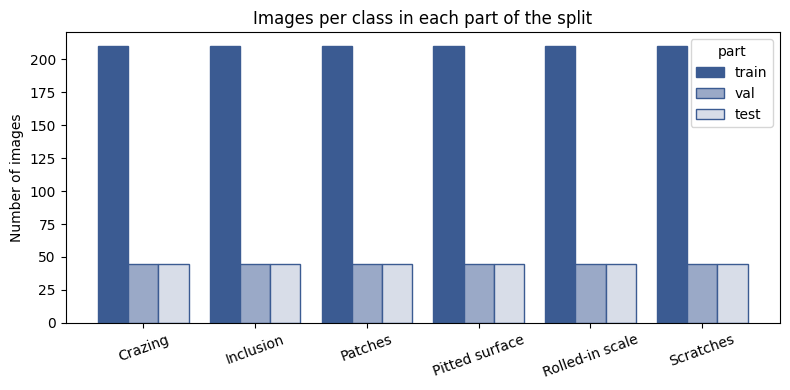

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CLASSES))
width = 0.27
for i, (name, color) in enumerate((("train", "#3b5b92"), ("val", "#9aa9c7"), ("test", "#d8dde8"))):
    ax.bar(x + (i - 1) * width, counts.loc[CLASSES, name], width, label=name, color=color, edgecolor="#3b5b92")
ax.set_xticks(x, [CLASS_NAMES[c] for c in CLASSES], rotation=20)
ax.set_ylabel("Number of images")
ax.set_title("Images per class in each part of the split")
ax.legend(title="part")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_01_class_balance.png", dpi=150)
plt.show()

## EDA 2 · Five random training images per class

Looking at several examples shows how much one class varies, and which classes could be mistaken for each other.

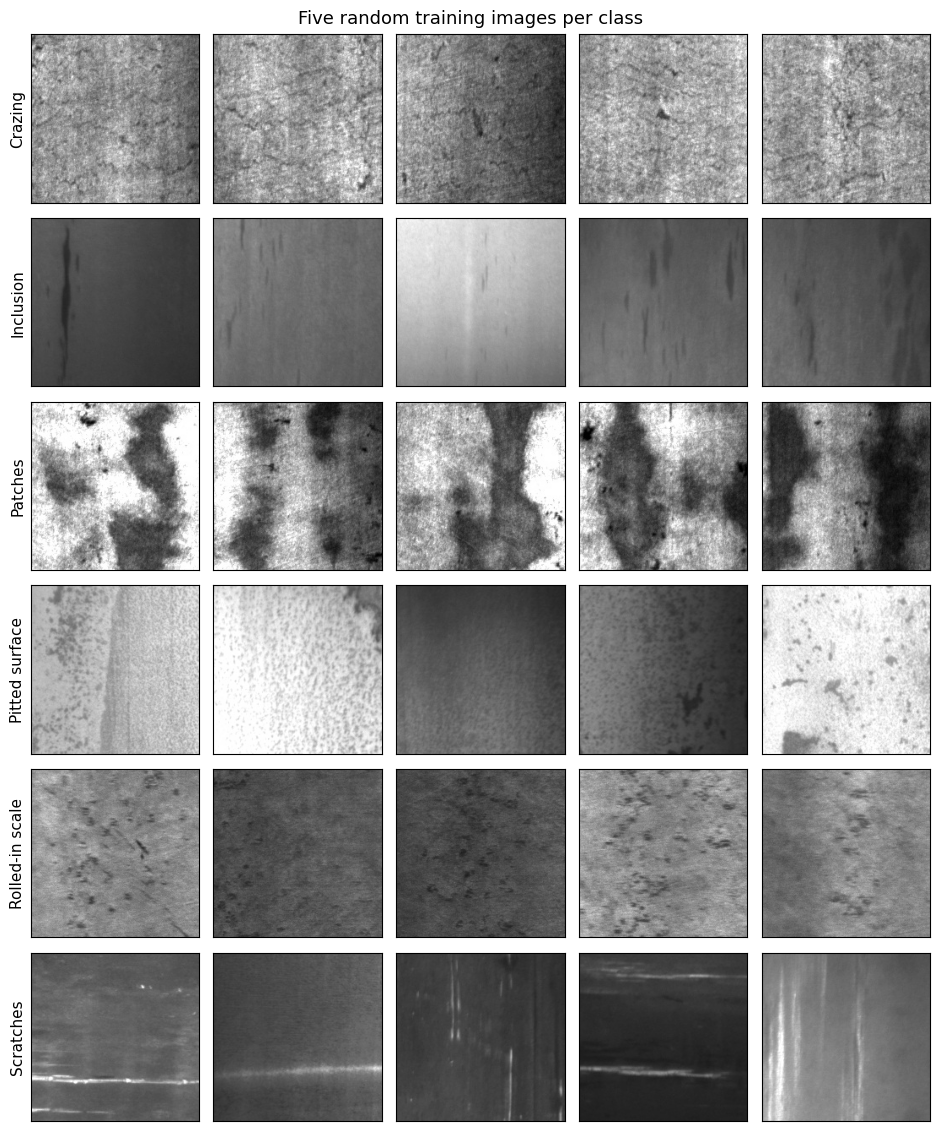

In [6]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(9.5, 11.5))
for row, label in enumerate(CLASSES):
    picks = rng.choice(np.flatnonzero(labels == label), size=5, replace=False)
    for col, idx in enumerate(picks):
        ax = axes[row, col]
        ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(CLASS_NAMES[label], fontsize=11)
fig.suptitle("Five random training images per class", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_02_sample_grid.png", dpi=150)
plt.show()

## EDA 3 · The average image of each class

Averaging all training images of one class washes out the random detail and keeps what is common, such as a preferred direction. If a class mean is just flat grey, that class has no fixed position or orientation, and the model has to learn local texture instead.

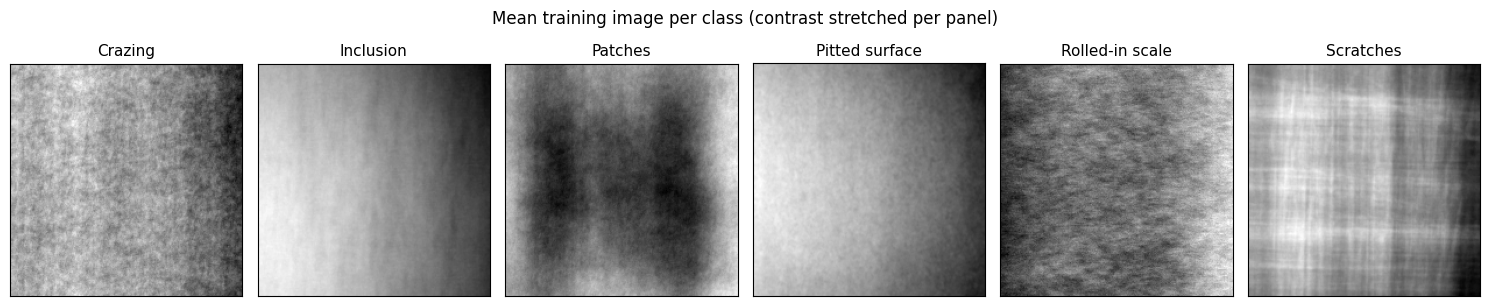

In [7]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(15, 3.2))
class_means = {}
for ax, label in zip(axes, CLASSES):
    mean_img = images[labels == label].mean(axis=0)
    class_means[label] = mean_img
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Mean training image per class (contrast stretched per panel)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_03_mean_image_per_class.png", dpi=150)
plt.show()

## EDA 4 · Pixel brightness histograms

Each curve shows how often each grey level (0 = black, 255 = white) appears in one class. Curves that sit on top of each other mean brightness alone cannot tell those classes apart.

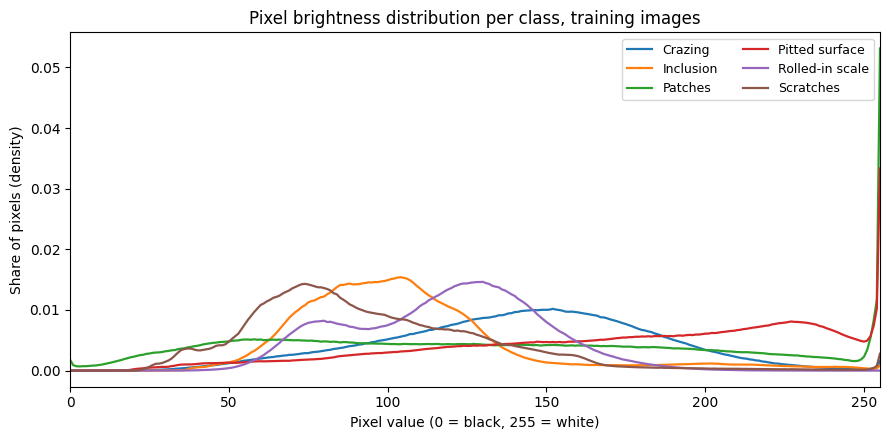

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(257)
for label in CLASSES:
    hist, _ = np.histogram(images[labels == label], bins=bins, density=True)
    ax.plot(bins[:-1], hist, label=CLASS_NAMES[label], linewidth=1.6)
ax.set_xlabel("Pixel value (0 = black, 255 = white)")
ax.set_ylabel("Share of pixels (density)")
ax.set_title("Pixel brightness distribution per class, training images")
ax.set_xlim(0, 255)
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_04_intensity_histograms.png", dpi=150)
plt.show()

## EDA 5 · Brightness and contrast of each image

For every image we take its mean pixel value (how bright it is) and its standard deviation (how much contrast it has). If one of these alone separated the classes, a CNN would be overkill.

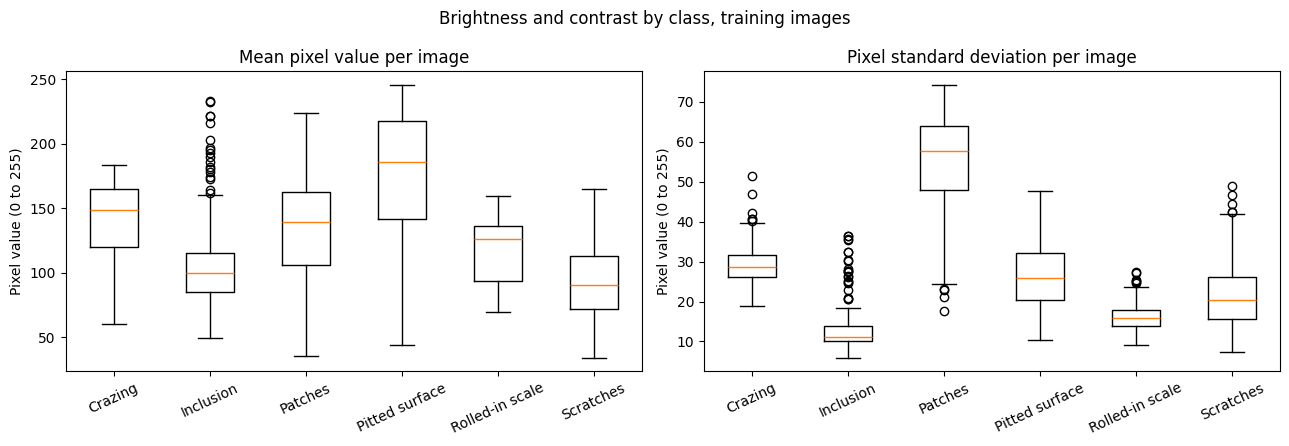

brightness                          contrast                 
                     median        min         max     median   min        max
label                                                                         
crazing          148.699997  60.200001  183.399994  28.600000  19.0  51.500000
inclusion         99.699997  49.900002  233.399994  11.200000   6.0  36.500000
patches          139.100006  35.599998  223.699997  57.799999  17.6  74.199997
pitted_surface   186.000000  44.500000  245.600006  25.900000  10.4  47.599998
rolled-in_scale  126.500000  69.500000  159.800003  15.900000   9.2  27.500000
scratches         90.400002  34.299999  165.100006  20.400000   7.4  49.000000

In [9]:
train["brightness"] = images.mean(axis=(1, 2))
train["contrast"] = images.std(axis=(1, 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, column, title in ((axes[0], "brightness", "Mean pixel value per image"), (axes[1], "contrast", "Pixel standard deviation per image")):
    data = [train.loc[train["label"] == c, column] for c in CLASSES]
    ax.boxplot(data, tick_labels=[CLASS_NAMES[c] for c in CLASSES])
    ax.set_title(title)
    ax.set_ylabel("Pixel value (0 to 255)")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Brightness and contrast by class, training images", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_05_brightness_contrast_boxplots.png", dpi=150)
plt.show()

brightness_table = train.groupby("label")[["brightness", "contrast"]].agg(["median", "min", "max"]).round(1)
brightness_table

## EDA 6 · Do the classes separate in raw pixel space?

PCA squeezes each image (here shrunk to 50 × 50 = 2,500 pixel values) down to the two directions that vary most across the training set. If the six classes formed clean clusters in this plot, a simple model on raw pixels might do. Overlap means we need a model that learns its own features, which is what a CNN does.

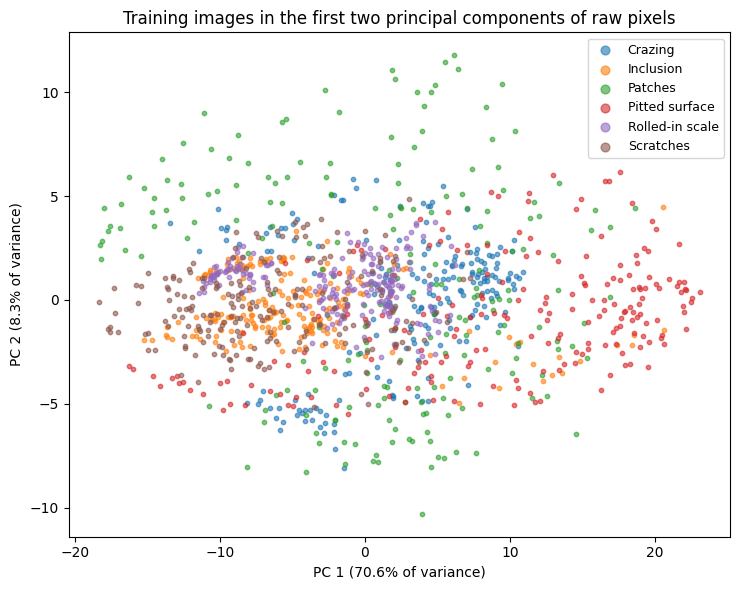

correlation between PC 1 and image brightness: 1.000


In [10]:
small = np.stack([np.asarray(Image.fromarray(img.astype(np.uint8)).resize((50, 50), Image.BILINEAR), dtype=np.float32).ravel() / 255.0 for img in images])
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(small)

fig, ax = plt.subplots(figsize=(7.5, 6))
for label in CLASSES:
    mask = labels == label
    ax.scatter(coords[mask, 0], coords[mask, 1], s=10, alpha=0.6, label=CLASS_NAMES[label])
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("Training images in the first two principal components of raw pixels")
ax.legend(markerscale=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_06_pca_raw_pixels.png", dpi=150)
plt.show()

pc1_vs_brightness = float(np.corrcoef(coords[:, 0], train["brightness"])[0, 1])
print(f"correlation between PC 1 and image brightness: {pc1_vs_brightness:.3f}")

## Save the EDA numbers

In [11]:
eda_summary = {
    "train_images": int(len(train)),
    "image_shape": list(images.shape[1:]),
    "brightness_median_by_class": {k: round(float(v), 2) for k, v in train.groupby("label")["brightness"].median().items()},
    "contrast_median_by_class": {k: round(float(v), 2) for k, v in train.groupby("label")["contrast"].median().items()},
    "pca_variance_ratio_pc1_pc2": [round(float(v), 4) for v in pca.explained_variance_ratio_],
    "pc1_brightness_correlation": round(pc1_vs_brightness, 3),
    "figures": sorted(p.name for p in FIG_DIR.glob("eda_*.png")),
}
(RES_DIR / "eda_summary.json").write_text(json.dumps(eda_summary, indent=2))
print(json.dumps(eda_summary, indent=2))

{
  "train_images": 1260,
  "image_shape": [
    200,
    200
  ],
  "brightness_median_by_class": {
    "crazing": 148.67,
    "inclusion": 99.74,
    "patches": 139.12,
    "pitted_surface": 186.05,
    "rolled-in_scale": 126.53,
    "scratches": 90.36
  },
  "contrast_median_by_class": {
    "crazing": 28.55,
    "inclusion": 11.18,
    "patches": 57.75,
    "pitted_surface": 25.92,
    "rolled-in_scale": 15.89,
    "scratches": 20.35
  },
  "pca_variance_ratio_pc1_pc2": [
    0.7063,
    0.0828
  ],
  "pc1_brightness_correlation": 1.0,
  "figures": [
    "eda_01_class_balance.png",
    "eda_02_sample_grid.png",
    "eda_03_mean_image_per_class.png",
    "eda_04_intensity_histograms.png",
    "eda_05_brightness_contrast_boxplots.png",
    "eda_06_pca_raw_pixels.png"
  ]
}


## What we found

- **The split is exact:** 210 / 45 / 45 images per class in train / validation / test, and no picture is in two parts. Running this notebook a second time gave byte-identical split files.
- **Brightness alone cannot tell the classes apart.** The histograms overlap heavily, and the brightness ranges of all six classes overlap in the boxplot, even though the medians differ (from 90.4 for scratches to 186.1 for pitted surface).
- **Contrast singles out one class:** patches have by far the most contrast (median pixel standard deviation 57.8; the other classes 11.2 to 28.5). Inclusion (11.2) and rolled-in scale (15.9) are the flattest images.
- **Some images are over-exposed:** patches and pitted surface have a spike at pixel value 255, so parts of those images are pure white.
- **The lighting is uneven:** the mean images of crazing, inclusion, pitted surface and scratches get darker towards the right edge. That comes from the camera and lights, not from the defect, so the model should not rely on it. Random horizontal flips during training put that dark edge on the left half the time.
- **Scratches run both ways:** the mean scratch image shows vertical and horizontal lines.
- **Raw pixels do not separate the classes.** PCA's first component holds 70.6 % of the pixel variance, and it is simply overall brightness (correlation with image brightness: 1.0). Along it, pitted surface sits to the right (bright) and scratches to the left (dark), while crazing, inclusion and rolled-in scale overlap. The useful information is texture and shape, which is what convolution layers learn.